# NB03 - Validasi dan Analisis Hasil Simulasi

Notebook ini memvalidasi perhitungan CIEDE2000, memeriksa konsistensi dua jalur implementasi Machado, mengukur ΔE00 setiap pasangan citra, lalu meringkas hasil menurut tipe simulasi dan severity.

In [9]:
%pip install opencv-python-headless numpy pandas matplotlib scikit-image -q

Note: you may need to restart the kernel to use updated packages.


## Tahap 1 - Setup dan Memuat Laporan Simulasi

In [10]:
from __future__ import annotations
import sys, time
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from skimage.color import deltaE_ciede2000
CORE_CANDIDATES = [Path.cwd() / "core", *[p / "core" for p in Path.cwd().parents]]
CORE_DIR = next((p for p in CORE_CANDIDATES if (p / "utils.py").exists()), None)
if CORE_DIR is None:
    raise FileNotFoundError("Folder core/ tidak ditemukan")
if str(CORE_DIR) not in sys.path:
    sys.path.insert(0, str(CORE_DIR))
from machado import simulate_machado_bgr
from utils import find_research_root, sha256_file, write_csv, write_json
RESEARCH_ROOT=find_research_root("notebooks/02/output/simulation_report.csv")
SIMULATION_REPORT_PATH=RESEARCH_ROOT/"notebooks/02/output/simulation_report.csv"
OUTPUT_DIR=RESEARCH_ROOT/"notebooks/03/output"
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
CVD_FAMILIES=("protan","deutan")
SEVERITIES=(0.25,0.50,0.75,1.00)
CONFORMANCE_TOLERANCE=0.00005

simulation_report=pd.read_csv(SIMULATION_REPORT_PATH).sort_values(["cvd_family","severity","source_class","source_file_name"]).reset_index(drop=True)
required={"subset","source_class","source_file_name","input_path","output_path","cvd_family","severity"}
missing=required-set(simulation_report.columns)
if missing: raise ValueError(f"Kolom laporan simulasi tidak lengkap: {sorted(missing)}")
if simulation_report.empty: raise RuntimeError("Laporan simulasi kosong.")
source_count=simulation_report[["subset","source_class","source_file_name"]].drop_duplicates().shape[0]
print(f"Pasangan citra yang dievaluasi: {len(simulation_report)}")

Pasangan citra yang dievaluasi: 28832


## Tahap 2 - Uji Kesesuaian CIEDE2000

In [11]:
# Pasangan acuan Sharma et al. (2005), digunakan untuk menguji implementasi CIEDE2000.
CIEDE2000_REFERENCE = [
    ((50.0000, 2.6772, -79.7751), (50.0000, 0.0000, -82.7485), 2.0425),
    ((50.0000, 3.1571, -77.2803), (50.0000, 0.0000, -82.7485), 2.8615),
    ((50.0000, 2.8361, -74.0200), (50.0000, 0.0000, -82.7485), 3.4412),
    ((50.0000, -1.3802, -84.2814), (50.0000, 0.0000, -82.7485), 1.0000),
    ((50.0000, -1.1848, -84.8006), (50.0000, 0.0000, -82.7485), 1.0000),
    ((50.0000, -0.9009, -85.5211), (50.0000, 0.0000, -82.7485), 1.0000),
    ((50.0000, 0.0000, 0.0000), (50.0000, -1.0000, 2.0000), 2.3669),
    ((50.0000, -1.0000, 2.0000), (50.0000, 0.0000, 0.0000), 2.3669),
    ((50.0000, 2.4900, -0.0010), (50.0000, -2.4900, 0.0009), 7.1792),
    ((50.0000, 2.4900, -0.0010), (50.0000, -2.4900, 0.0010), 7.1792),
    ((50.0000, 2.4900, -0.0010), (50.0000, -2.4900, 0.0011), 7.2195),
    ((50.0000, 2.4900, -0.0010), (50.0000, -2.4900, 0.0012), 7.2195),
    ((50.0000, -0.0010, 2.4900), (50.0000, 0.0009, -2.4900), 4.8045),
    ((50.0000, -0.0010, 2.4900), (50.0000, 0.0010, -2.4900), 4.8045),
    ((50.0000, -0.0010, 2.4900), (50.0000, 0.0011, -2.4900), 4.7461),
    ((50.0000, 2.5000, 0.0000), (50.0000, 0.0000, -2.5000), 4.3065),
    ((50.0000, 2.5000, 0.0000), (73.0000, 25.0000, -18.0000), 27.1492),
    ((50.0000, 2.5000, 0.0000), (61.0000, -5.0000, 29.0000), 22.8977),
    ((50.0000, 2.5000, 0.0000), (56.0000, -27.0000, -3.0000), 31.9030),
    ((50.0000, 2.5000, 0.0000), (58.0000, 24.0000, 15.0000), 19.4535),
    ((50.0000, 2.5000, 0.0000), (50.0000, 3.1736, 0.5854), 1.0000),
    ((50.0000, 2.5000, 0.0000), (50.0000, 3.2972, 0.0000), 1.0000),
    ((50.0000, 2.5000, 0.0000), (50.0000, 1.8634, 0.5757), 1.0000),
    ((50.0000, 2.5000, 0.0000), (50.0000, 3.2592, 0.3350), 1.0000),
    ((60.2574, -34.0099, 36.2677), (60.4626, -34.1751, 39.4387), 1.2644),
    ((63.0109, -31.0961, -5.8663), (62.8187, -29.7946, -4.0864), 1.2630),
    ((61.2901, 3.7196, -5.3901), (61.4292, 2.2480, -4.9620), 1.8731),
    ((35.0831, -44.1164, 3.7933), (35.0232, -40.0716, 1.5901), 1.8645),
    ((22.7233, 20.0904, -46.6940), (23.0331, 14.9730, -42.5619), 2.0373),
    ((36.4612, 47.8580, 18.3852), (36.2715, 50.5065, 21.2231), 1.4146),
    ((90.8027, -2.0831, 1.4410), (91.1528, -1.6435, 0.0447), 1.4441),
    ((90.9257, -0.5406, -0.9208), (88.6381, -0.8985, -0.7239), 1.5381),
    ((6.7747, -0.2908, -2.4247), (5.8714, -0.0985, -2.2286), 0.6377),
    ((2.0776, 0.0795, -1.1350), (0.9033, -0.0636, -0.5514), 0.9082),
]

In [12]:
conformance_rows=[]
for case_id,(lab_a,lab_b,expected) in enumerate(CIEDE2000_REFERENCE,start=1):
    observed=float(deltaE_ciede2000(np.array(lab_a)[None,None,:],np.array(lab_b)[None,None,:])[0,0])
    absolute_error=abs(observed-expected)
    conformance_rows.append({"case_id":case_id,"expected_delta_e00":expected,"observed_delta_e00":observed,"absolute_error":absolute_error,"passed":absolute_error<=CONFORMANCE_TOLERANCE})
conformance=pd.DataFrame(conformance_rows)
if not conformance["passed"].all(): raise RuntimeError("Uji kesesuaian CIEDE2000 tidak memenuhi toleransi.")
print(f"Seluruh {len(conformance)} pasangan acuan memenuhi toleransi.")

Seluruh 34 pasangan acuan memenuhi toleransi.


## Tahap 3 - Menghitung ΔE00 Setiap Pasangan Citra

In [13]:
def mean_delta_e00(input_bgr: np.ndarray, output_bgr: np.ndarray) -> float:
    first=cv2.cvtColor(input_bgr,cv2.COLOR_BGR2LAB).astype(np.float64)
    second=cv2.cvtColor(output_bgr,cv2.COLOR_BGR2LAB).astype(np.float64)
    first[:,:,0]*=100.0/255.0; second[:,:,0]*=100.0/255.0
    first[:,:,1:]-=128.0; second[:,:,1:]-=128.0
    return float(deltaE_ciede2000(first,second).mean())

started = time.perf_counter()
evaluation_rows=[]
for index,row in simulation_report.iterrows():
    original=cv2.imread(row["input_path"],cv2.IMREAD_COLOR)
    simulated=cv2.imread(row["output_path"],cv2.IMREAD_COLOR)
    if original is None or simulated is None or original.shape != simulated.shape: raise ValueError(f"Pasangan citra tidak valid: {row['output_path']}")
    evaluation_rows.append({"subset":row["subset"],"source_class":row["source_class"],"source_file_name":row["source_file_name"],"cvd_family":row["cvd_family"],"severity":row["severity"],"input_path":row["input_path"],"output_path":row["output_path"],"mean_delta_e00":mean_delta_e00(original,simulated)})
    if (index+1)%1000==0 or index+1==len(simulation_report): print(f"{index+1}/{len(simulation_report)} pasangan dievaluasi, {time.perf_counter()-started:.1f} detik")
evaluation=pd.DataFrame(evaluation_rows).sort_values(["cvd_family","severity","source_class","source_file_name"]).reset_index(drop=True)
print(f"Rata-rata ΔE00 keseluruhan: {evaluation['mean_delta_e00'].mean():.4f}")

1000/28832 pasangan dievaluasi, 144.3 detik
2000/28832 pasangan dievaluasi, 281.1 detik
3000/28832 pasangan dievaluasi, 427.3 detik
4000/28832 pasangan dievaluasi, 566.1 detik
5000/28832 pasangan dievaluasi, 687.2 detik
6000/28832 pasangan dievaluasi, 807.5 detik
7000/28832 pasangan dievaluasi, 928.1 detik
8000/28832 pasangan dievaluasi, 1055.0 detik
9000/28832 pasangan dievaluasi, 1187.2 detik
10000/28832 pasangan dievaluasi, 1317.5 detik
11000/28832 pasangan dievaluasi, 1451.3 detik
12000/28832 pasangan dievaluasi, 1589.9 detik
13000/28832 pasangan dievaluasi, 1725.5 detik
14000/28832 pasangan dievaluasi, 1855.1 detik
15000/28832 pasangan dievaluasi, 1983.3 detik
16000/28832 pasangan dievaluasi, 2112.9 detik
17000/28832 pasangan dievaluasi, 2240.2 detik
18000/28832 pasangan dievaluasi, 2368.8 detik
19000/28832 pasangan dievaluasi, 2478.0 detik
20000/28832 pasangan dievaluasi, 2586.1 detik
21000/28832 pasangan dievaluasi, 2696.6 detik
22000/28832 pasangan dievaluasi, 2803.1 detik
2300

In [18]:
FIGURE_DIR = OUTPUT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

def read_bgr(path: str) -> np.ndarray:
    image = cv2.imread(path, cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f"Citra tidak dapat dibaca: {path}")
    return image


def calculate_delta_e00_map(
    original_bgr: np.ndarray,
    simulated_bgr: np.ndarray,
) -> np.ndarray:
    original_lab = cv2.cvtColor(
        original_bgr,
        cv2.COLOR_BGR2LAB,
    ).astype(np.float64)

    simulated_lab = cv2.cvtColor(
        simulated_bgr,
        cv2.COLOR_BGR2LAB,
    ).astype(np.float64)

    original_lab[:, :, 0] *= 100.0 / 255.0
    simulated_lab[:, :, 0] *= 100.0 / 255.0

    original_lab[:, :, 1:] -= 128.0
    simulated_lab[:, :, 1:] -= 128.0

    return deltaE_ciede2000(original_lab, simulated_lab)

In [20]:
def select_examples(group: pd.DataFrame) -> pd.DataFrame:
    cvd_family, severity = group.name

    ordered = group.sort_values(
        ["mean_delta_e00", "source_class", "source_file_name"]
    ).reset_index(drop=True)

    median_value = ordered["mean_delta_e00"].median()

    median_index = (
        (ordered["mean_delta_e00"] - median_value)
        .abs()
        .sort_values(kind="stable")
        .index[0]
    )

    examples = pd.concat(
        [
            ordered.iloc[[0]].assign(example_type="terendah"),
            ordered.loc[[median_index]].assign(
                example_type="mendekati_median"
            ),
            ordered.iloc[[-1]].assign(example_type="tertinggi"),
        ],
        ignore_index=True,
    )

    examples["cvd_family"] = cvd_family
    examples["severity"] = severity

    return examples.drop_duplicates(
        subset=[
            "source_class",
            "source_file_name",
            "cvd_family",
            "severity",
        ]
    )


representative_cases = (
    evaluation.groupby(
        ["cvd_family", "severity"],
        group_keys=False,
    )
    .apply(select_examples, include_groups=False)
    .reset_index(drop=True)
)

write_csv(
    representative_cases,
    OUTPUT_DIR / "representative_cases.csv",
    ["cvd_family", "severity", "example_type"],
)

representative_cases[
    [
        "cvd_family",
        "severity",
        "example_type",
        "source_class",
        "source_file_name",
        "mean_delta_e00",
    ]
]

,cvd_family,severity,example_type,source_class,source_file_name,mean_delta_e00
0,deutan,0.25,terendah,003pear,127.png,0.172222
1,deutan,0.25,mendekati_median,009peach,155.png,5.300080
2,deutan,0.25,tertinggi,004tomato,191.png,11.385384
3,deutan,0.50,terendah,003pear,112.png,0.419287
4,deutan,0.50,mendekati_median,004tomato,354.png,9.442202
5,deutan,0.50,tertinggi,004tomato,191.png,21.779424
6,deutan,0.75,terendah,003pear,112.png,0.551371
7,deutan,0.75,mendekati_median,001apple,224.png,12.499265
8,deutan,0.75,tertinggi,004tomato,191.png,30.160398
9,deutan,1.00,terendah,003pear,112.png,0.656965


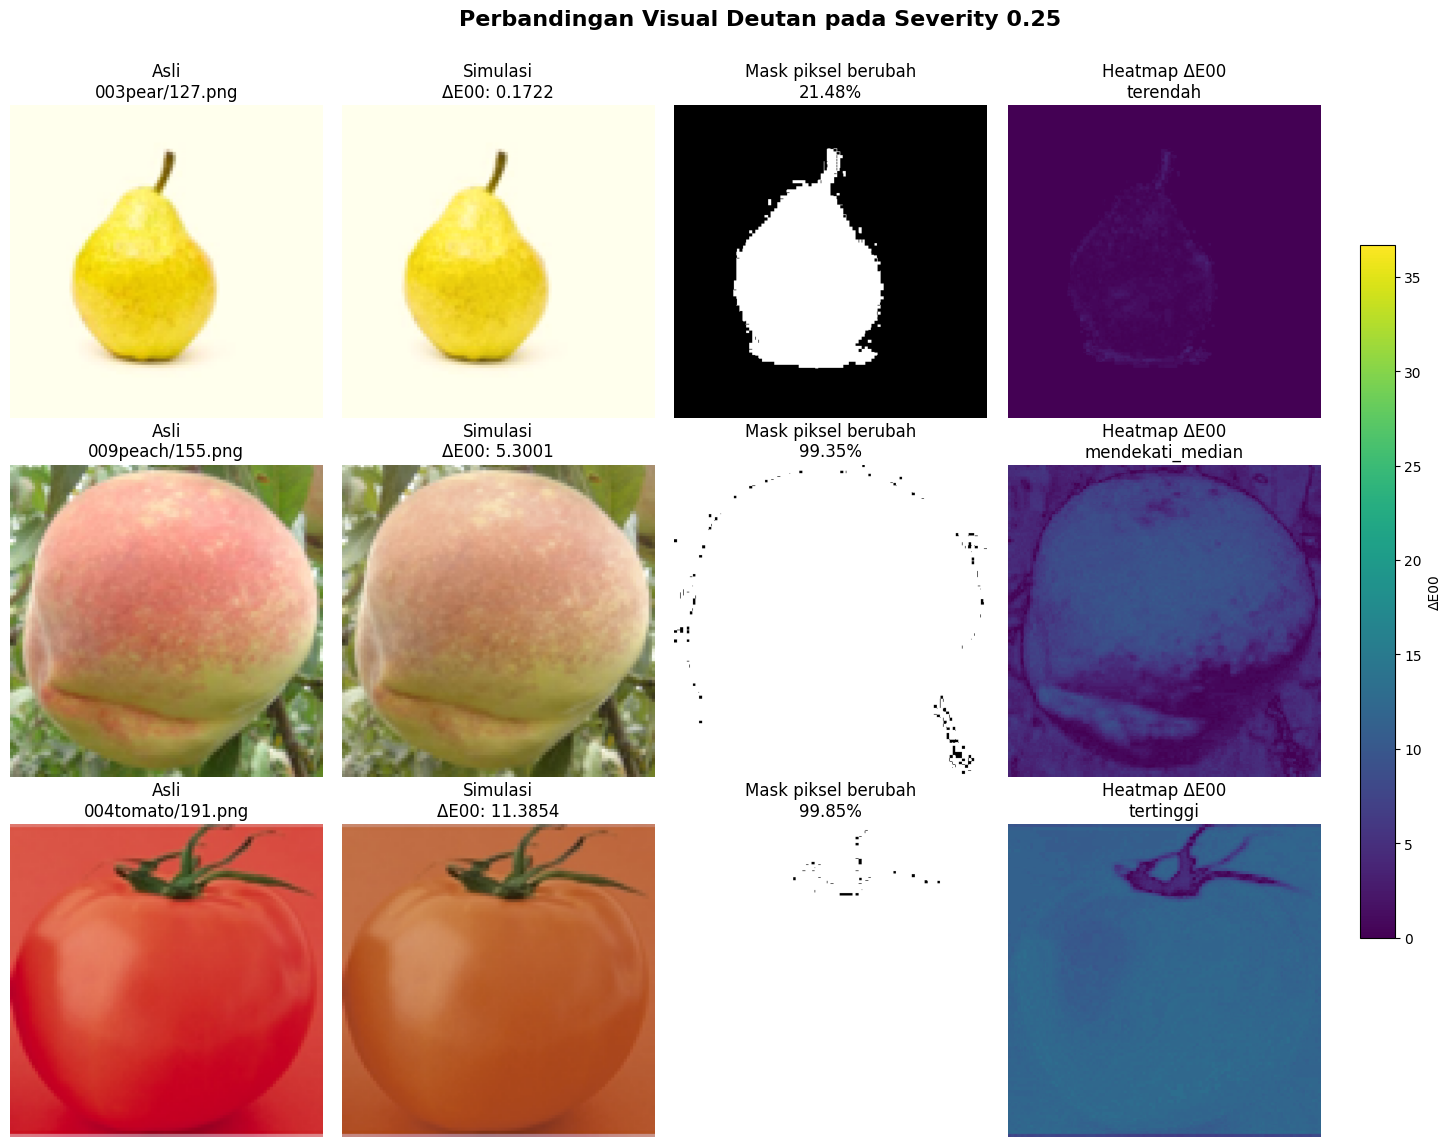

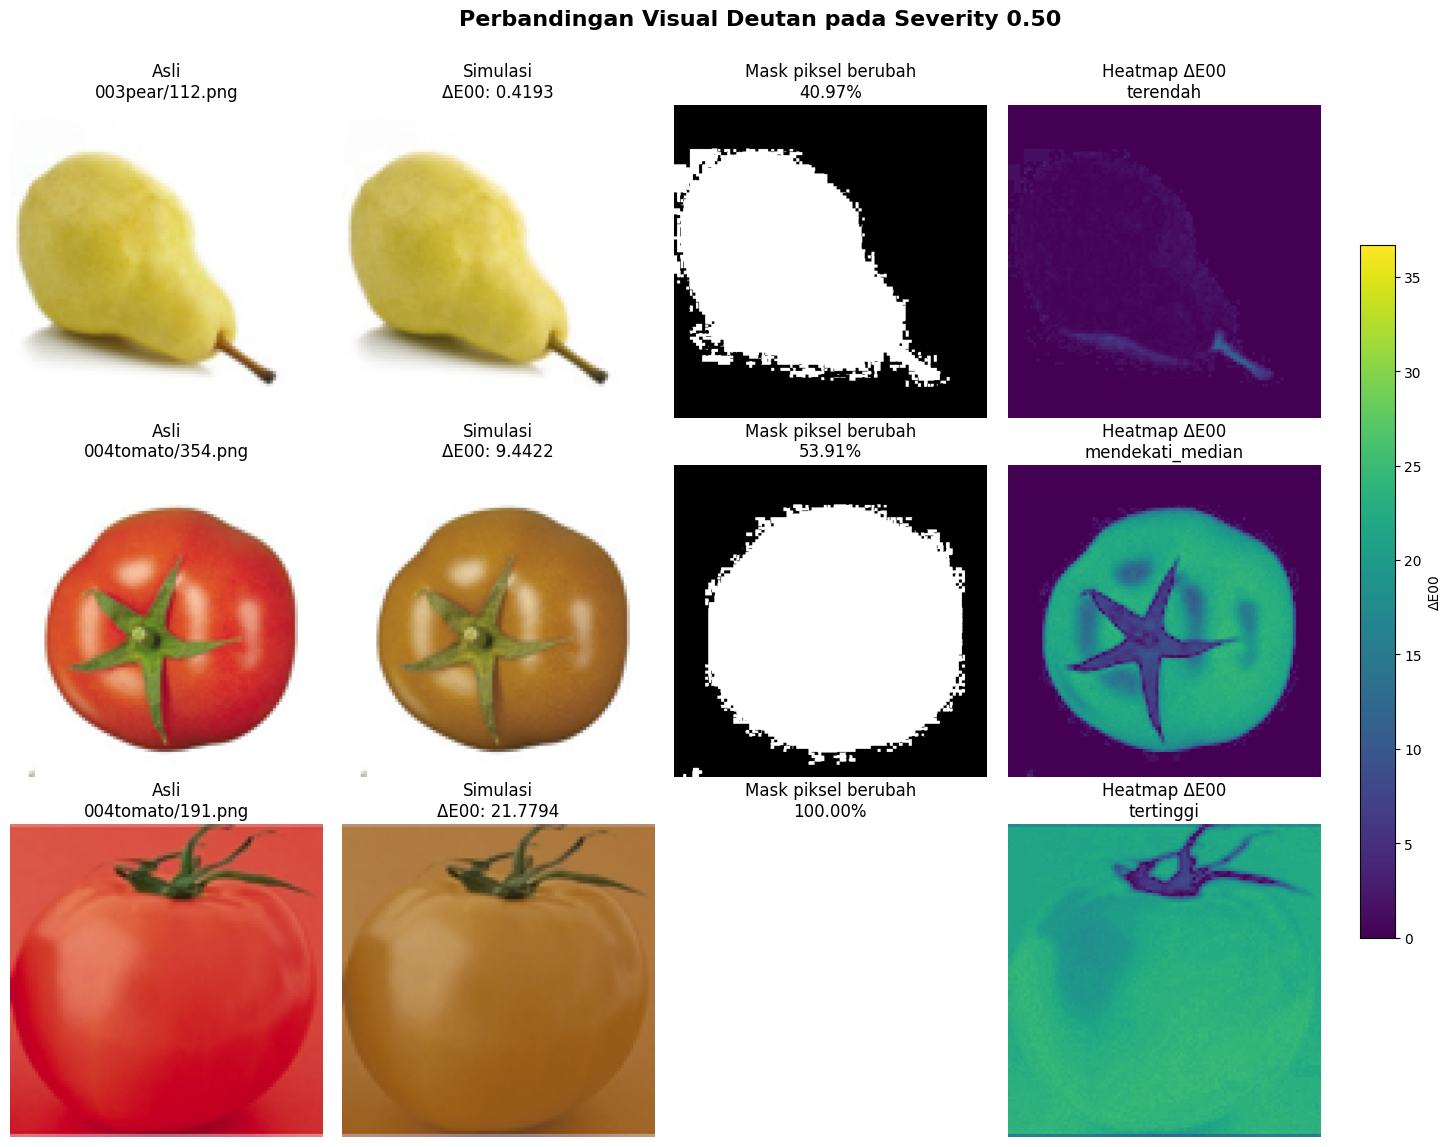

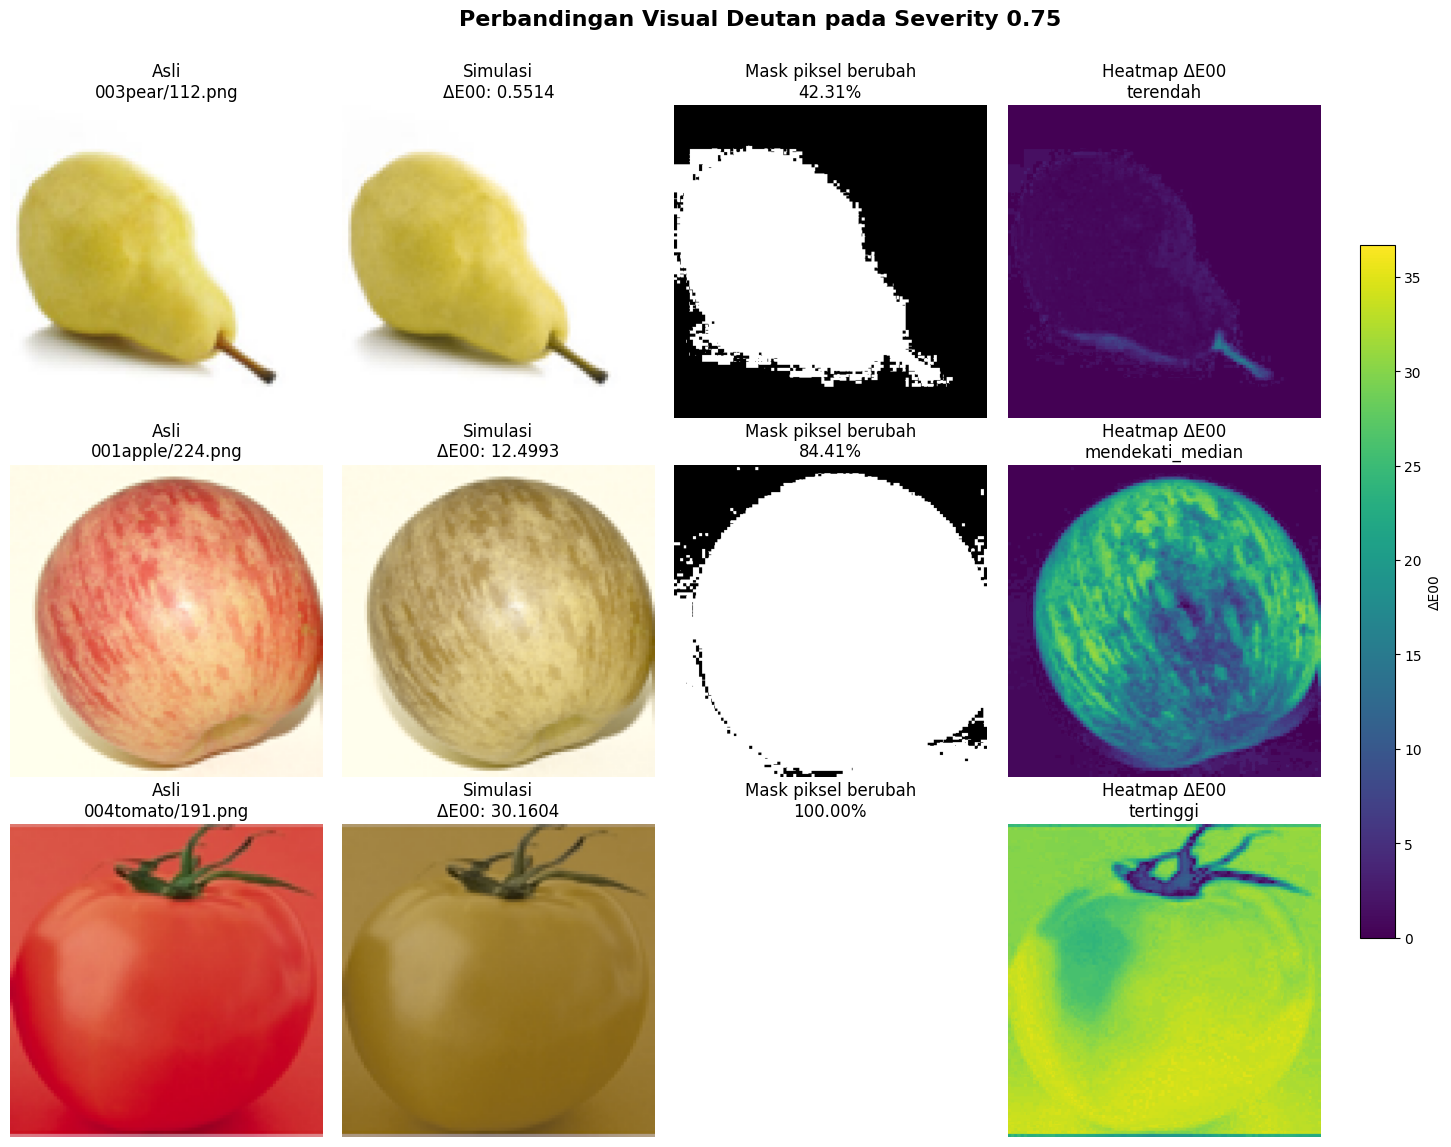

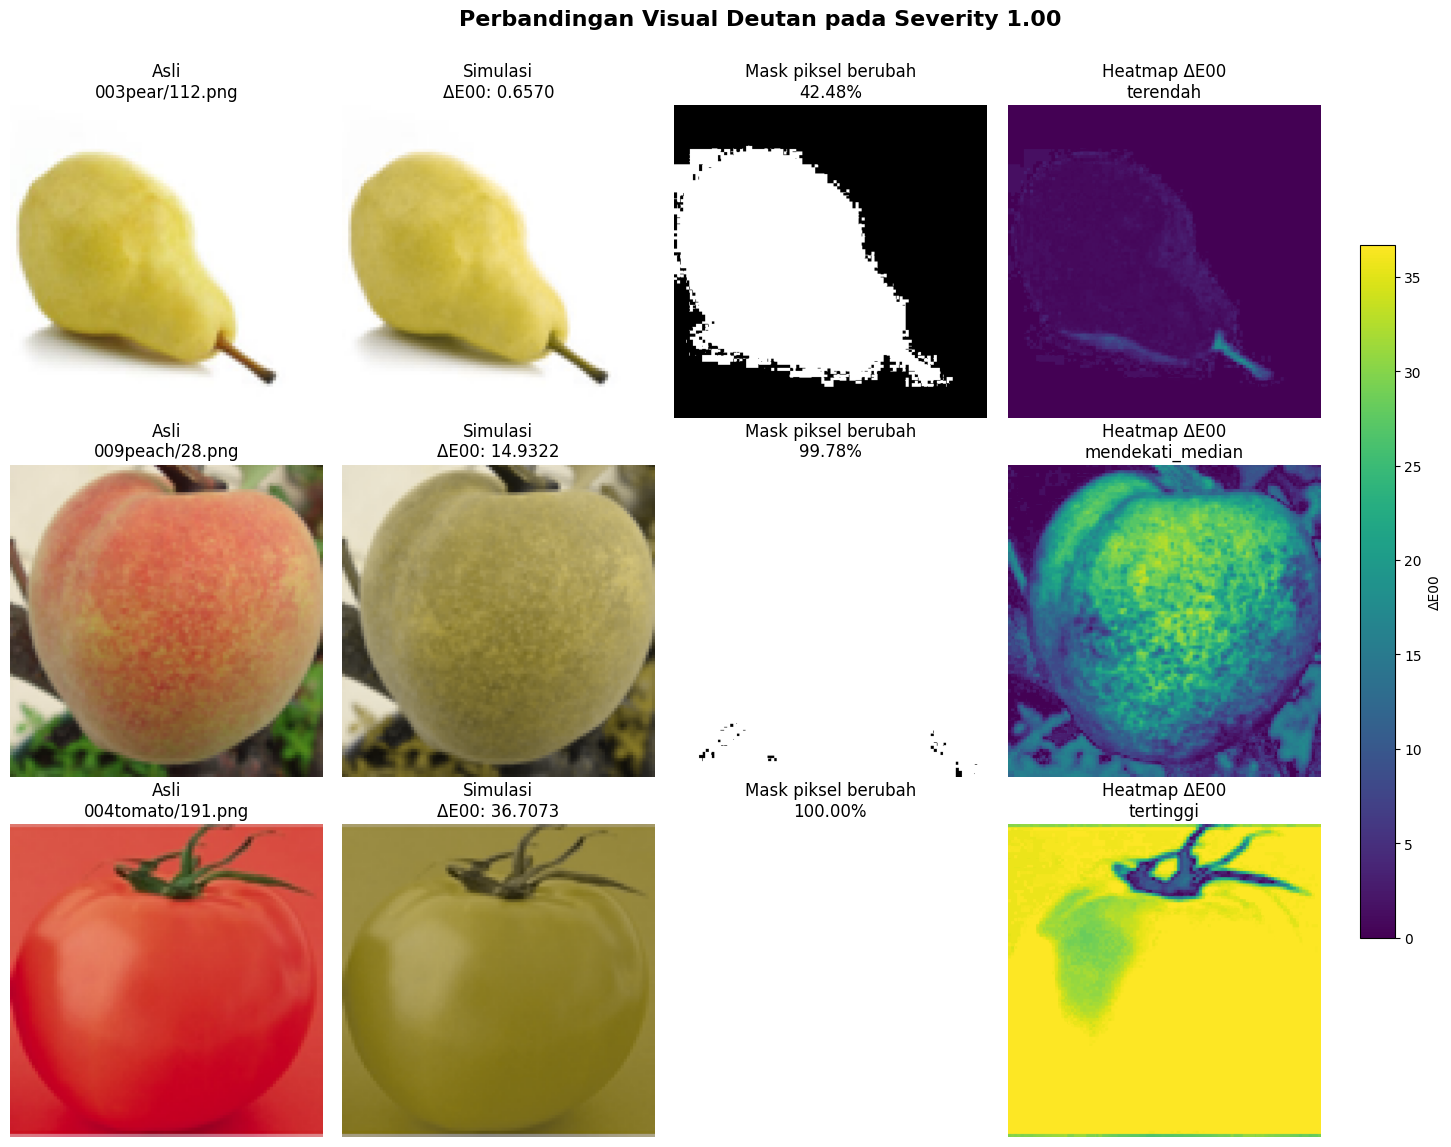

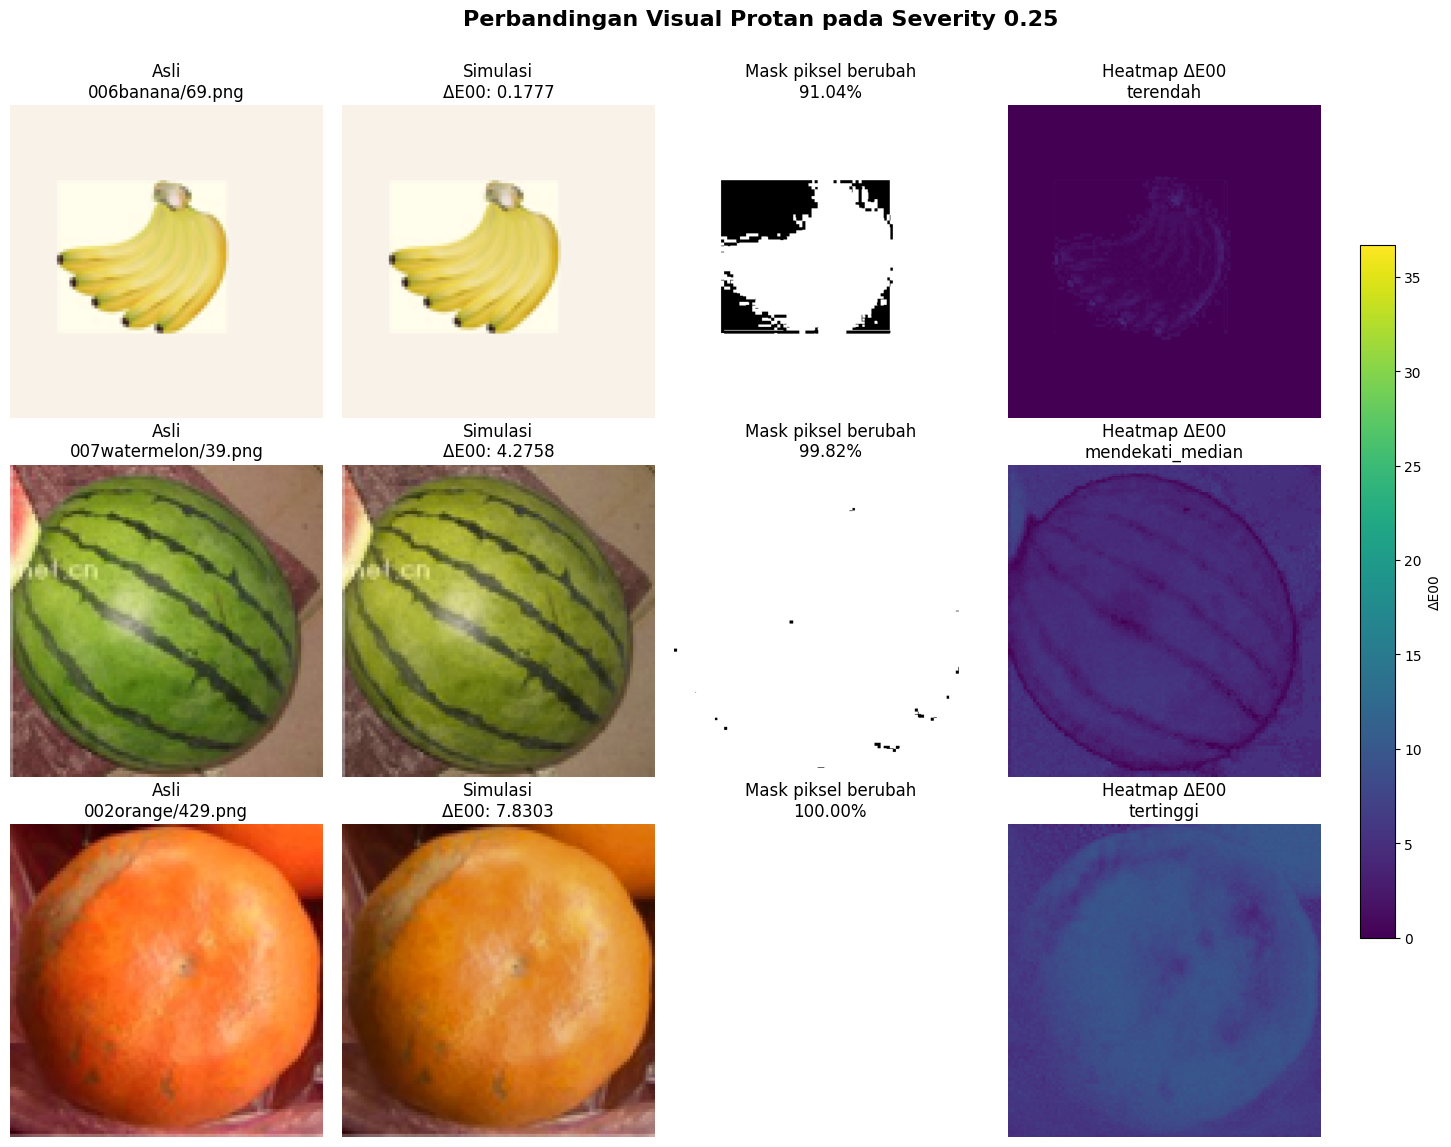

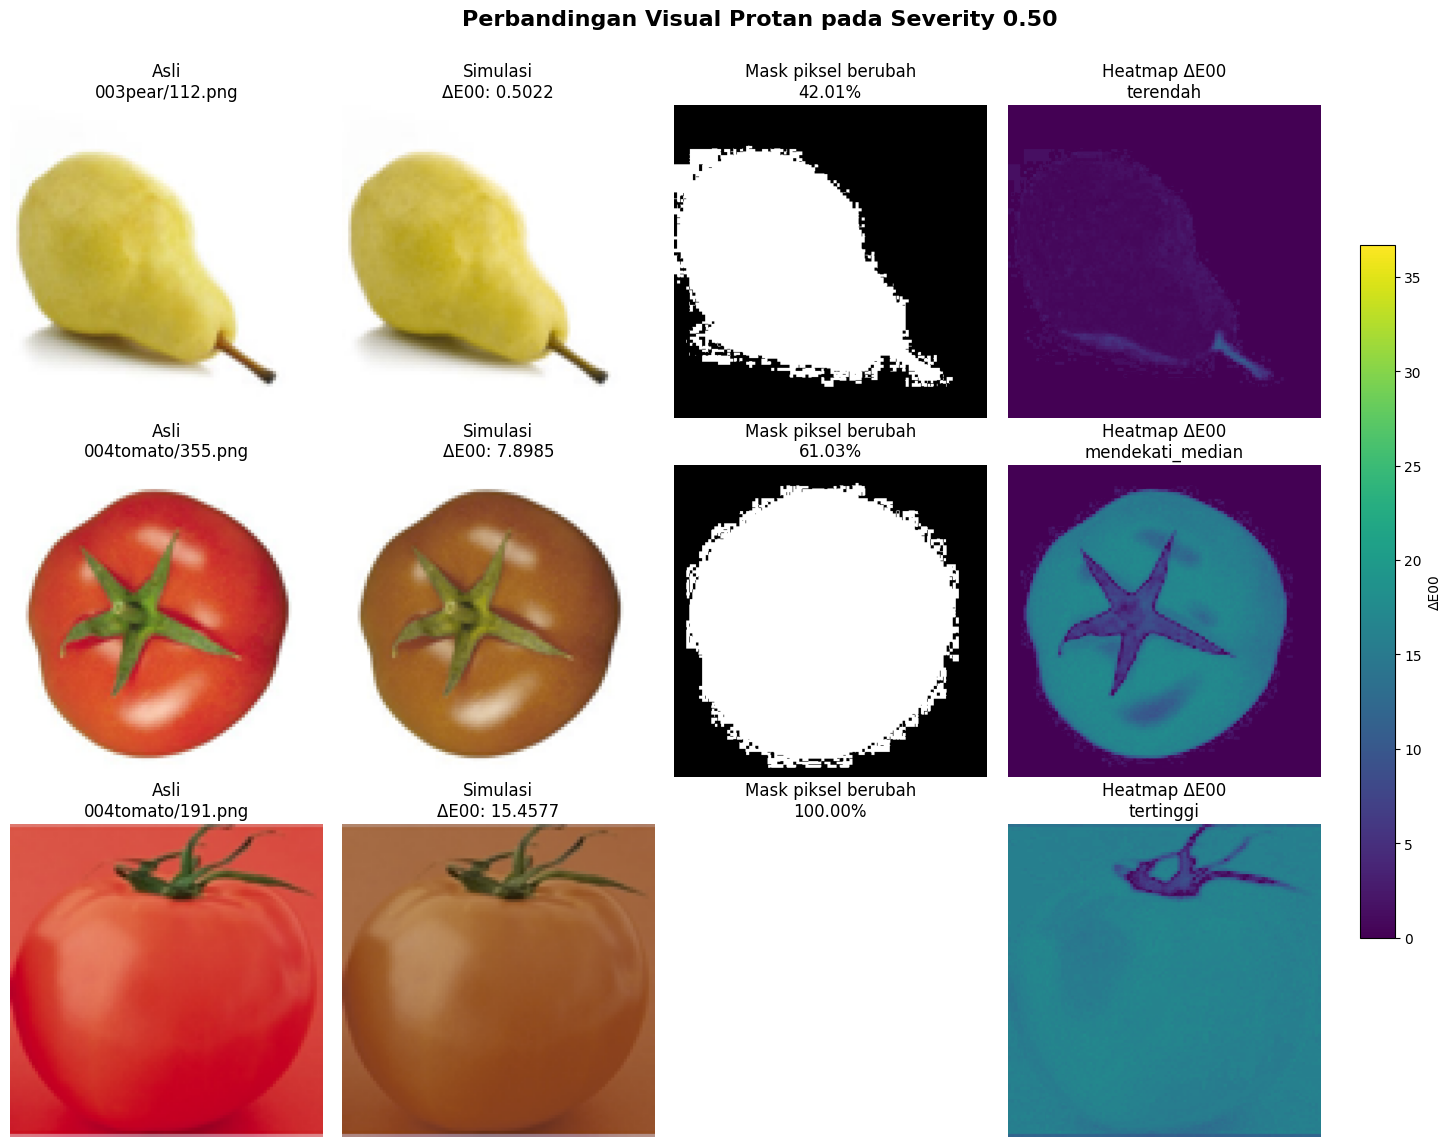

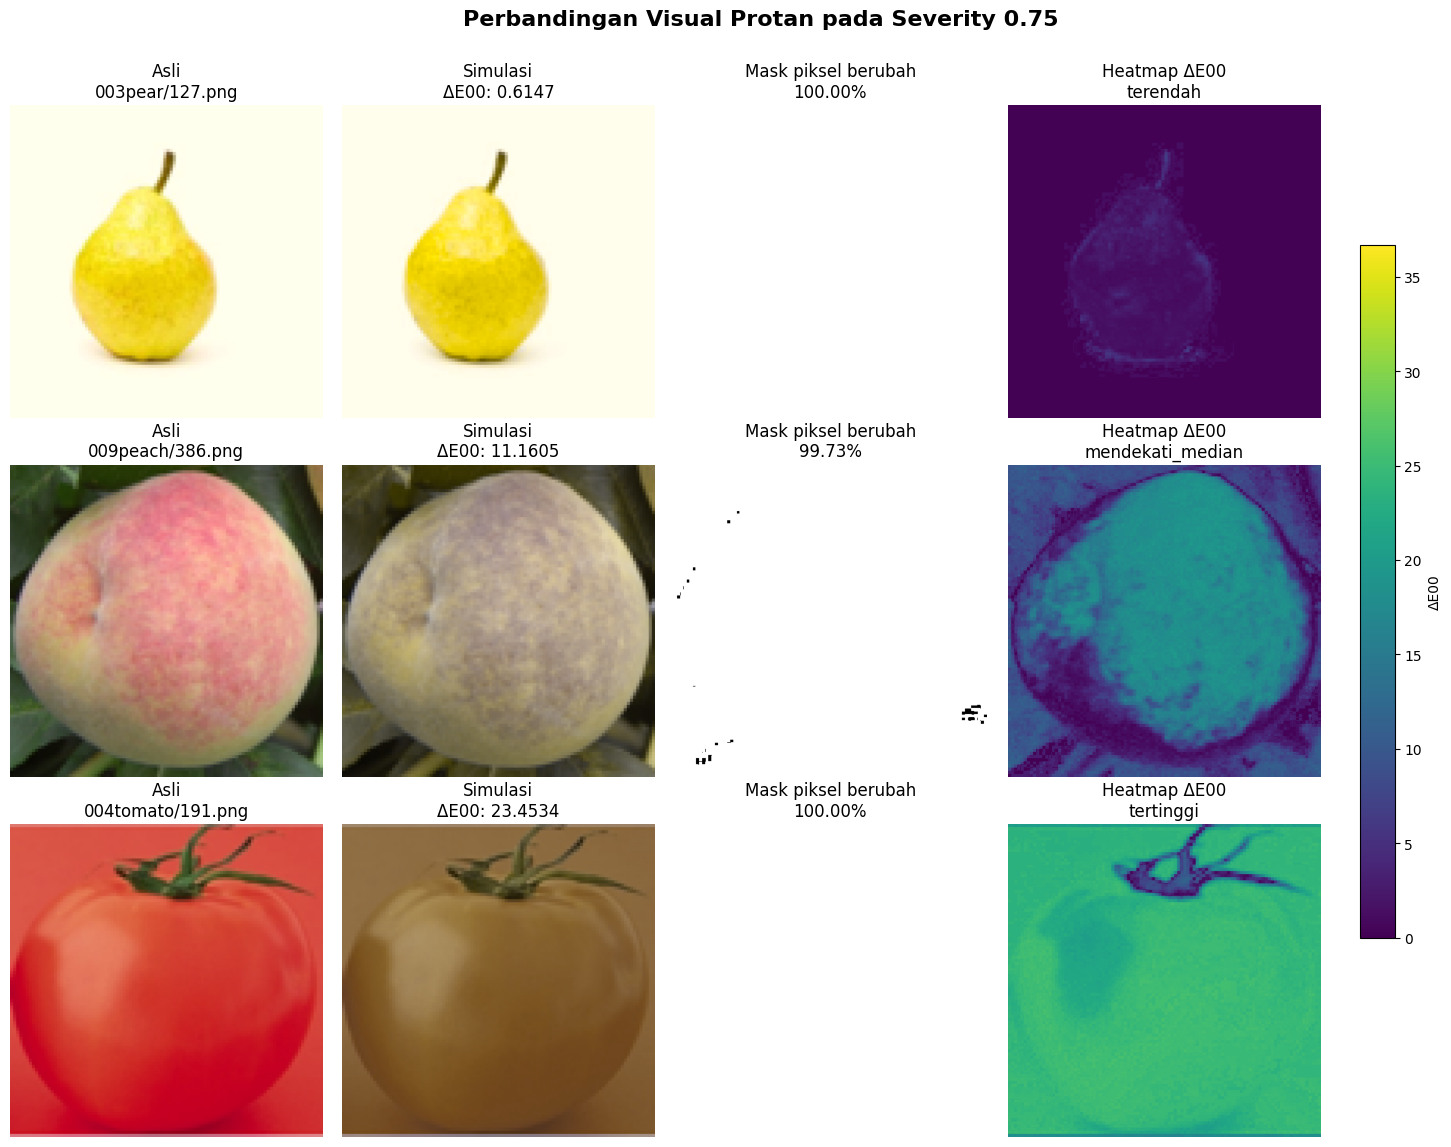

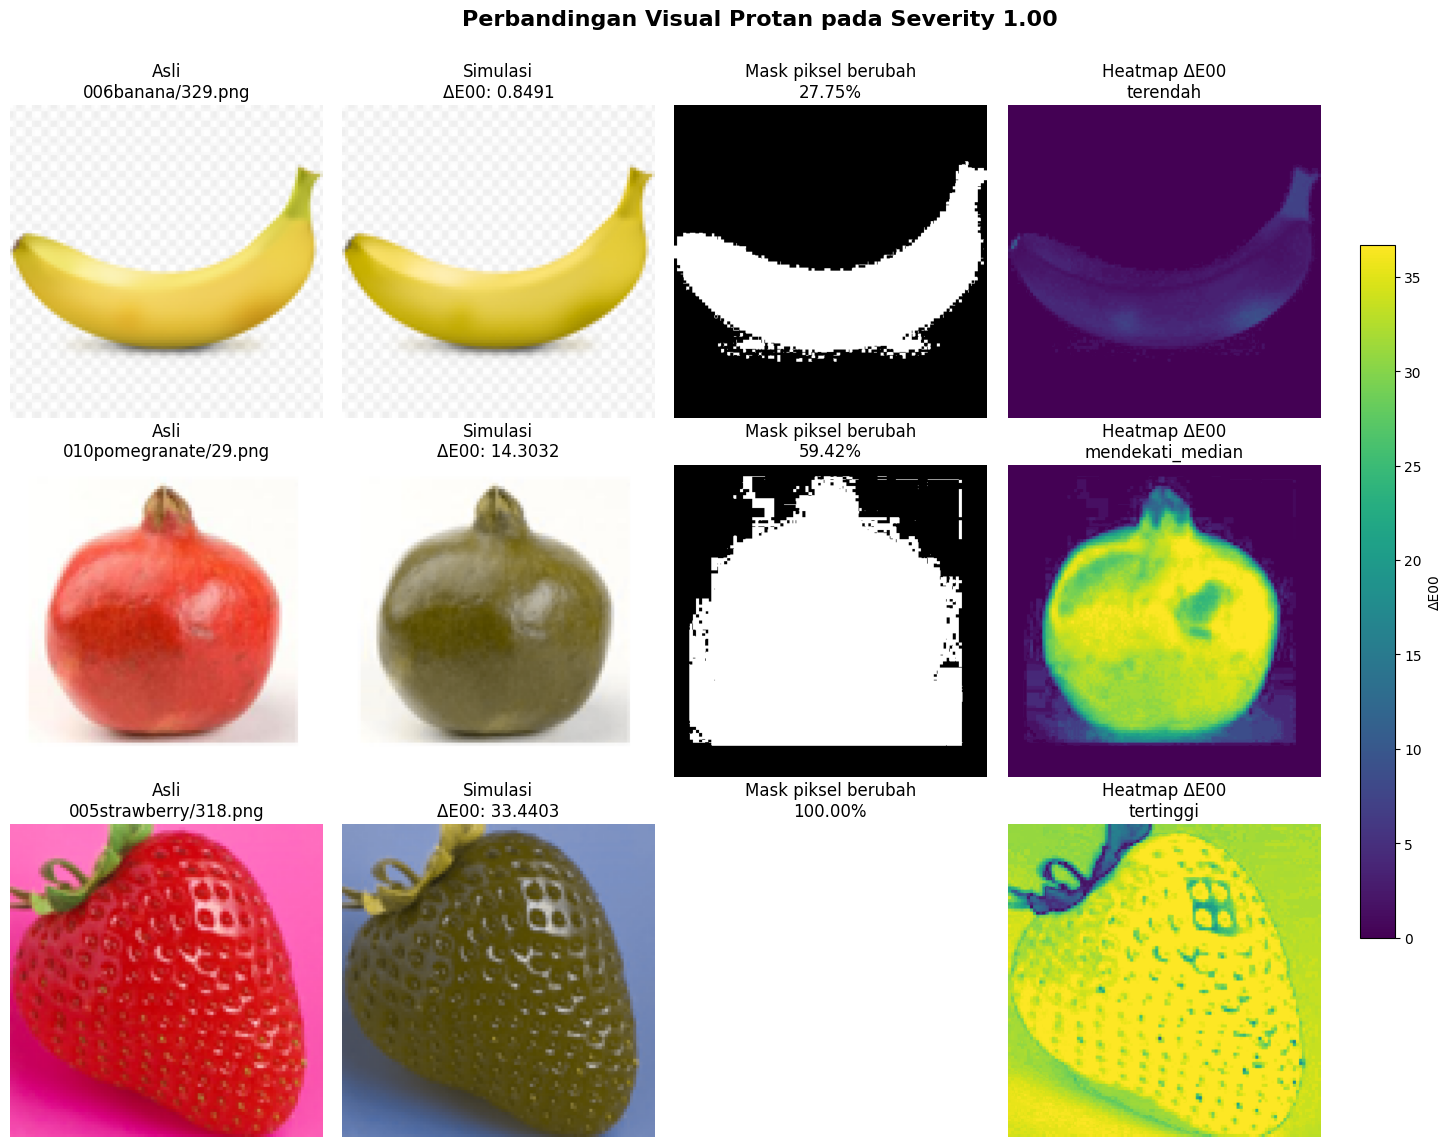

In [27]:
delta_e00_max = float(evaluation["mean_delta_e00"].max())

example_order = {
    "terendah": 0,
    "mendekati_median": 1,
    "tertinggi": 2,
}


def create_visual_panel(cases: pd.DataFrame) -> None:
    ordered_cases = cases.sort_values(
        "example_type",
        key=lambda values: values.map(example_order),
    )

    figure, axes = plt.subplots(3, 4, figsize=(16, 12))

    for row_index, (_, item) in enumerate(ordered_cases.iterrows()):
        original_bgr = read_bgr(item["input_path"])
        simulated_bgr = read_bgr(item["output_path"])

        delta_e00_map = calculate_delta_e00_map(
            original_bgr,
            simulated_bgr,
        )

        changed_mask = np.any(
            original_bgr != simulated_bgr,
            axis=2,
        )

        axes[row_index, 0].imshow(
            cv2.cvtColor(original_bgr, cv2.COLOR_BGR2RGB)
        )
        axes[row_index, 0].set_title(
            f"Asli\n{item['source_class']}/{item['source_file_name']}"
        )

        axes[row_index, 1].imshow(
            cv2.cvtColor(simulated_bgr, cv2.COLOR_BGR2RGB)
        )
        axes[row_index, 1].set_title(
            f"Simulasi\nΔE00: {item['mean_delta_e00']:.4f}"
        )

        axes[row_index, 2].imshow(
            changed_mask,
            cmap="gray",
            vmin=0,
            vmax=1,
        )
        axes[row_index, 2].set_title(
            f"Mask piksel berubah\n{changed_mask.mean():.2%}"
        )

        heatmap = axes[row_index, 3].imshow(
            delta_e00_map,
            cmap="viridis",
            vmin=0,
            vmax=delta_e00_max,
        )
        axes[row_index, 3].set_title(
            f"Heatmap ΔE00\n{item['example_type']}"
        )

        for axis in axes[row_index]:
            axis.axis("off")

    figure.colorbar(
        heatmap,
        ax=axes[:, 3],
        shrink=0.75,
        label="ΔE00",
    )

    cvd_family = ordered_cases.iloc[0]["cvd_family"]
    severity = ordered_cases.iloc[0]["severity"]

    figure.suptitle(
        f"Perbandingan Visual {cvd_family.title()} "
        f"pada Severity {severity:.2f}",
        fontsize=16,
        fontweight="bold",
    )

    figure.subplots_adjust(
        top=0.90,
        bottom=0.04,
        left=0.03,
        right=0.85,
        hspace=0.15,
        wspace=0.05,
    )

    output_path = (
        FIGURE_DIR
        / f"visual_{cvd_family}_severity_{int(severity * 100):03d}.png"
    )

    figure.savefig(
        output_path,
        dpi=180,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(figure)


for _, cases in representative_cases.groupby(
    ["cvd_family", "severity"],
):
    create_visual_panel(cases)

## Tahap 4 - Agregasi, Visualisasi, dan Ekspor Hasil

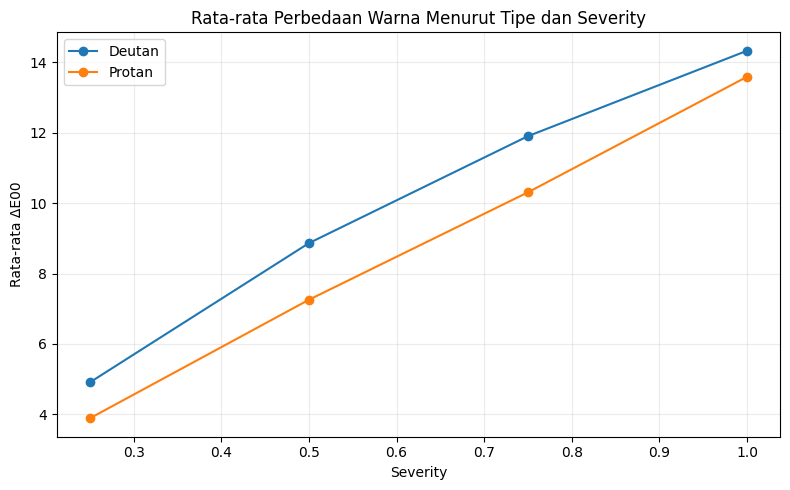

,cvd_family,severity,image_count,mean_delta_e00,median_delta_e00,minimum_delta_e00,maximum_delta_e00
0,deutan,0.25,3604,4.907354,5.300384,0.172222,11.385384
1,deutan,0.50,3604,8.862914,9.444780,0.419287,21.779424
2,deutan,0.75,3604,11.902578,12.499524,0.551371,30.160398
3,deutan,1.00,3604,14.328258,14.936242,0.656965,36.707321
4,protan,0.25,3604,3.887620,4.276420,0.177650,7.830335
5,protan,0.50,3604,7.254980,7.896299,0.502202,15.457719
6,protan,0.75,3604,10.307814,11.164023,0.614685,23.453378
7,protan,1.00,3604,13.589408,14.313086,0.849115,33.440335


In [31]:
group_summary=evaluation.groupby(["cvd_family","severity"],as_index=False).agg(image_count=("mean_delta_e00","size"),mean_delta_e00=("mean_delta_e00","mean"),median_delta_e00=("mean_delta_e00","median"),minimum_delta_e00=("mean_delta_e00","min"),maximum_delta_e00=("mean_delta_e00","max"))
write_csv(conformance,OUTPUT_DIR/"ciede2000_conformance.csv",["case_id"])
write_csv(
    representative_cases,
    OUTPUT_DIR / "representative_cases.csv",
    [
        "cvd_family",
        "severity",
        "example_type",
    ],
)

write_csv(
    group_summary,
    OUTPUT_DIR / "evaluation_group_summary.csv",
    ["cvd_family", "severity"],
)
write_json({"evaluated_pair_count":len(evaluation),"overall_mean_delta_e00":float(evaluation.mean_delta_e00.mean()),"ciede2000_conformance_passed":bool(conformance.passed.all()),"ciede2000_conformance_case_count":len(conformance),"ciede2000_conformance_tolerance":CONFORMANCE_TOLERANCE},OUTPUT_DIR/"evaluation_summary.json")
plt.figure(figsize=(8,5))
for family,group in group_summary.groupby("cvd_family"):
    plt.plot(group["severity"],group["mean_delta_e00"],marker="o",label=family.title())
plt.xlabel("Severity"); plt.ylabel("Rata-rata ΔE00"); plt.title("Rata-rata Perbedaan Warna Menurut Tipe dan Severity"); plt.legend(); plt.grid(alpha=.25); plt.tight_layout(); plt.savefig(OUTPUT_DIR/"mean_delta_e00_by_condition.png",dpi=180,bbox_inches="tight"); plt.show()
group_summary